# ACA 1 · Computación en la Nube
## Ingesta, vectorización y almacenamiento vectorial en la nube para un sistema RAG clínico

**Especialización en Inteligencia Artificial · CUN** · Docente: Hamilton Rivera Flor

| Elemento | Decisión |
|---|---|
| Pilar | 🩺 **Salud**: asistente cloud de consulta clínica, diagnóstico asistido y protocolos |
| Datasets base | UCI *Heart Disease* (920 pacientes) + UCI *Breast Cancer Wisconsin (Diagnostic)* (569 biopsias) |
| Corpus complementario | 3 documentos: guía de riesgo cardiovascular, guía de cáncer de mama, protocolo de bioseguridad y consentimiento (`data/corpus/`) |
| Base vectorial cloud | **Supabase (PostgreSQL + pgvector)**, índice HNSW, distancia coseno |
| Embeddings | **EmbeddingGemma (Google) ejecutado localmente con Ollama**: 768 dimensiones, costo $0, el texto clínico no sale del equipo |
| Chunking | `RecursiveCharacterTextSplitter` por secciones (800 / 120) |

**Flujo:** aprovisionar → ingerir → chunking → embeddings locales + *batch upsert* a la nube → búsqueda semántica → validación cuantitativa.

> 🔐 Las credenciales se leen **solo** desde variables de entorno (`.env`). No hay claves en el código.

In [17]:
%pip install -q requests "psycopg[binary]" pgvector langchain-text-splitters pypdf python-dotenv pandas numpy matplotlib


[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import os, time, hashlib, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from dotenv import load_dotenv

# Raíz del proyecto: funciona si el notebook se abre desde la raíz o desde notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
load_dotenv(ROOT / ".env")


def get_secret(name, default=None):
    """Lee un secreto desde variables de entorno (.env) o, en Colab, desde Secrets."""
    value = os.environ.get(name)
    if value:
        return value
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return default


DATABASE_URL = get_secret("DATABASE_URL")
OLLAMA_HOST = get_secret("OLLAMA_HOST", "http://localhost:11434").rstrip("/")
EMBED_MODEL = get_secret("EMBED_MODEL", "embeddinggemma-2")
EMBED_DIM = int(get_secret("EMBED_DIM", "768"))
TABLE = "rag_salud"

assert DATABASE_URL, "Falta DATABASE_URL en .env (o en Secrets de Colab)"
print(f"Raíz del proyecto: {ROOT}")
print(f"Credenciales cargadas desde el entorno ✔ (no se imprimen) | Ollama={OLLAMA_HOST} | modelo={EMBED_MODEL} | dim={EMBED_DIM}")

Raíz del proyecto: /Users/juanreyes/ESP-rag
Credenciales cargadas desde el entorno ✔ (no se imprimen) | Ollama=http://localhost:11434 | modelo=embeddinggemma-2 | dim=768


## 1. Modelo de embeddings local (Ollama + EmbeddingGemma)

**¿Por qué un modelo local?**
- **Costo cero**: no hay API de pago ni cuotas; se puede re-vectorizar el corpus las veces que haga falta.
- **Privacidad**: en salud el texto puede contener información sensible; con Ollama el texto **nunca sale del equipo**, solo los vectores viajan a la nube.
- **EmbeddingGemma** (Google, ~300 M de parámetros) es multilingüe (más de 100 idiomas, incluido el español), produce vectores de **768 dimensiones** y acepta hasta 2.048 tokens por texto.

EmbeddingGemma se entrenó con **prefijos de tarea** (equivalentes al `RETRIEVAL_DOCUMENT` / `RETRIEVAL_QUERY` de Gemini):

| Uso | Formato del texto enviado al modelo |
|---|---|
| Fragmento del corpus | `title: {título} \| text: {contenido}` |
| Pregunta del usuario | `task: search result \| query: {pregunta}` |

Los vectores se normalizan (norma L2 = 1), así la similitud coseno de pgvector es consistente.

In [2]:
# 1) ¿Ollama está corriendo y tiene el modelo?
try:
    tags = requests.get(f"{OLLAMA_HOST}/api/tags", timeout=10).json()
except requests.exceptions.ConnectionError:
    raise SystemExit("No hay conexión con Ollama. Abre la app de Ollama o ejecuta `ollama serve` en una terminal.")

local_models = [m["name"] for m in tags.get("models", [])]
print("Modelos disponibles en Ollama:", local_models)
assert any(m.split(":")[0] == EMBED_MODEL.split(":")[0] for m in local_models), \
    f"El modelo '{EMBED_MODEL}' no está descargado. Ejecuta en una terminal: ollama pull {EMBED_MODEL}"


def _normalize(matrix):
    arr = np.asarray(matrix, dtype=np.float32)
    norms = np.linalg.norm(arr, axis=1, keepdims=True)
    norms[norms == 0] = 1
    return arr / norms


def ollama_embed(texts, batch_size=32):
    """Envía los textos a Ollama por lotes y devuelve una matriz (n, dim) normalizada."""
    vectors = []
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        for attempt in range(4):
            try:
                r = requests.post(f"{OLLAMA_HOST}/api/embed",
                                  json={"model": EMBED_MODEL, "input": batch, "truncate": True, "keep_alive": "10m"},
                                  timeout=300)
                r.raise_for_status()
                break
            except requests.exceptions.RequestException as exc:
                wait = 2 ** attempt
                print(f"  reintento {attempt + 1}/4 ({type(exc).__name__}); espero {wait}s")
                time.sleep(wait)
        else:
            raise RuntimeError("Ollama no respondió tras varios reintentos")
        vectors.extend(r.json()["embeddings"])
    return _normalize(vectors)


def embed_documents(records):
    """Prefijo de documento de EmbeddingGemma: 'title: ... | text: ...'."""
    return ollama_embed([f"title: {r.get('title') or 'none'} | text: {r['content']}" for r in records])


def embed_query(question):
    """Prefijo de consulta de EmbeddingGemma (recuperación)."""
    return ollama_embed([f"task: search result | query: {question}"])[0]


# 2) Prueba rápida y verificación de la dimensión
t0 = time.time()
test = embed_query("prueba de conexión")
print(f"Dimensión: {test.shape[0]} | norma L2: {np.linalg.norm(test):.4f} | latencia: {(time.time() - t0) * 1000:.0f} ms")
assert test.shape[0] == EMBED_DIM, f"El modelo devuelve {test.shape[0]} dimensiones pero EMBED_DIM={EMBED_DIM}. Ajusta EMBED_DIM en .env."

Modelos disponibles en Ollama: ['embeddinggemma-2:latest']
Dimensión: 768 | norma L2: 1.0000 | latencia: 62 ms


## 2. Aprovisionamiento cloud y conectividad (Supabase + pgvector)

- Conexión por el **Session pooler** de Supabase (IPv4, puerto 5432).
- Se crea la extensión `vector`, la tabla `rag_salud` con columna `vector(768)`, un índice **HNSW con distancia coseno** (`vector_cosine_ops`) y la función `match_salud`, reutilizable como RPC desde una API o un agente RAG.
- Se activa **RLS** para que la tabla no quede expuesta por la API pública de Supabase.
- El mismo SQL está en `sql/01_schema_salud.sql` por si prefieres ejecutarlo en el *SQL Editor* del panel.

In [3]:
import psycopg
from psycopg.rows import dict_row
from psycopg.types.json import Jsonb
from pgvector.psycopg import register_vector

SCHEMA_SQL = (ROOT / "sql" / "01_schema_salud.sql").read_text(encoding="utf-8").replace("768", str(EMBED_DIM))

# prepare_threshold=None -> compatible también con el pooler en modo transacción
conn = psycopg.connect(DATABASE_URL, prepare_threshold=None, autocommit=True)
conn.execute("set search_path = public, extensions")
print("Conectado a:", conn.execute("select version()").fetchone()[0][:60], "...")

conn.execute(SCHEMA_SQL)
register_vector(conn)

ext = conn.execute("select extversion from pg_extension where extname = 'vector'").fetchone()[0]
col_dim = conn.execute(f"select atttypmod from pg_attribute where attrelid = 'public.{TABLE}'::regclass and attname = 'embedding'").fetchone()[0]
idx = conn.execute(f"select indexdef from pg_indexes where tablename = '{TABLE}' and indexdef ilike '%hnsw%'").fetchone()[0]
assert col_dim == EMBED_DIM, f"La tabla tiene vector({col_dim}) y el modelo {EMBED_DIM}. Borra la tabla ({TABLE}) y vuelve a ejecutar."
print(f"pgvector {ext} ✔ | tabla public.{TABLE} con vector({col_dim}) ✔")
print("Índice:", idx)

Conectado a: PostgreSQL 17.6 on aarch64-unknown-linux-gnu, compiled by gc ...
pgvector 0.8.0 ✔ | tabla public.rag_salud con vector(768) ✔
Índice: CREATE INDEX rag_salud_embedding_hnsw ON public.rag_salud USING hnsw (embedding vector_cosine_ops) WITH (m='16', ef_construction='64')


## 3. Ingesta: datasets base y corpus documental

**Datasets estructurados (pilar Salud):**
- **UCI Heart Disease** (Janosi et al., 1988): 920 pacientes de Cleveland, Hungría, Suiza y VA Long Beach con 14 variables clínicas y el diagnóstico angiográfico `num` (0 = sin enfermedad; 1–4 = enfermedad coronaria).
- **UCI Breast Cancer Wisconsin – Diagnostic** (Wolberg et al., 1995): 569 biopsias por aspiración con aguja fina (BACAF) descritas por 30 características de los núcleos celulares y el diagnóstico maligno/benigno.

Sus **metadatos** (diccionario de variables) y **resúmenes estadísticos** se convierten en texto y se indexan junto al corpus, de modo que el asistente pueda responder tanto con la guía clínica como con evidencia de los datos.

In [4]:
DATA_DIR = ROOT / "data"
heart = pd.read_csv(DATA_DIR / "heart_disease_uci.csv")
breast = pd.read_csv(DATA_DIR / "BreastCancer.csv")
heart["enfermedad"] = heart["num"] > 0
HEART_NAME = "UCI Heart Disease"
BREAST_NAME = "UCI Breast Cancer Wisconsin (Diagnostic)"

print(f"{HEART_NAME}: {heart.shape[0]} filas x {heart.shape[1] - 1} columnas")
print(f"{BREAST_NAME}: {breast.shape[0]} filas x {breast.shape[1]} columnas\n")
display(pd.concat({
    "Heart Disease (num > 0)": heart["enfermedad"].map({True: "con enfermedad", False: "sin enfermedad"}).value_counts(),
    "Breast Cancer (diagnosis)": breast["diagnosis"].map({"M": "maligno", "B": "benigno"}).value_counts(),
}).to_frame("registros"))
display(heart.isna().sum().loc[lambda s: s > 0].to_frame("valores faltantes (Heart)").T)

UCI Heart Disease: 920 filas x 16 columnas
UCI Breast Cancer Wisconsin (Diagnostic): 569 filas x 32 columnas



registros
Heart Disease (num > 0)   con enfermedad        509
                          sin enfermedad        411
Breast Cancer (diagnosis) benigno               357
                          maligno               212

,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal
valores faltantes (Heart),59,30,90,2,55,55,62,309,611,486


**Corpus no estructurado:** se cargan todos los `.md`, `.txt` y `.pdf` de `data/corpus/`.
- Los Markdown se dividen primero por **secciones** (`## título`), y el título se guarda como metadato (y se usa en el prefijo `title:` de EmbeddingGemma).
- Los PDF se leen página por página y conservan el número de página.

> Puedes agregar PDF oficiales (p. ej. guías del MinSalud o de la OMS) en `data/corpus/` y volver a ejecutar: el pipeline los procesa sin cambios de código.

In [5]:
from pypdf import PdfReader

CORPUS_DIR = DATA_DIR / "corpus"


def split_markdown_sections(text):
    """Devuelve [(título_sección, texto)] usando los encabezados '## '."""
    doc_title = next((l[2:].strip() for l in text.splitlines() if l.startswith("# ")), None)
    parts = re.split(r"\n(?=## )", text)
    sections = []
    for part in parts:
        lines = part.strip().splitlines()
        if not lines:
            continue
        if lines[0].startswith("## "):
            sections.append((lines[0][3:].strip(), "\n".join(lines[1:]).strip()))
        else:  # preámbulo antes de la primera sección
            body = "\n".join(l for l in lines if not l.startswith("# ")).strip()
            if body:
                sections.append(("Introducción", body))
    return doc_title, sections


def load_corpus(corpus_dir):
    docs = []
    for path in sorted(corpus_dir.glob("*")):
        ext = path.suffix.lower()
        if ext in (".md", ".txt"):
            doc_title, sections = split_markdown_sections(path.read_text(encoding="utf-8"))
            for sec_title, body in sections:
                docs.append({"source": path.name, "doc_title": doc_title or path.stem, "section": sec_title, "page": None, "text": body})
        elif ext == ".pdf":
            for i, page in enumerate(PdfReader(str(path)).pages, start=1):
                text = (page.extract_text() or "").strip()
                if text:
                    docs.append({"source": path.name, "doc_title": path.stem, "section": f"Página {i}", "page": i, "text": text})
    return docs


docs = load_corpus(CORPUS_DIR)
assert docs, f"No se encontraron documentos en {CORPUS_DIR}"
corpus_summary = (pd.DataFrame(docs).assign(caracteres=lambda d: d["text"].str.len())
                  .groupby("source").agg(secciones=("text", "count"), caracteres=("caracteres", "sum"),
                                         seccion_media=("caracteres", "mean")).round(0))
display(corpus_summary)
print("Total de caracteres del corpus:", int(corpus_summary["caracteres"].sum()))

,secciones,caracteres,seccion_media
source,,,
guia_cancer_mama.md,9,4980,553.0
guia_riesgo_cardiovascular.md,11,7020,638.0
protocolo_bioseguridad_consentimiento.md,10,4956,496.0


Total de caracteres del corpus: 16956


## 4. Pipeline de chunking y justificación técnica

Se compara el efecto de distintos tamaños de chunk (con 15 % de solapamiento) sobre el número y la longitud de los fragmentos antes de elegir el valor final.

In [6]:
from langchain_text_splitters import RecursiveCharacterTextSplitter


def make_splitter(size, overlap):
    return RecursiveCharacterTextSplitter(
        chunk_size=size, chunk_overlap=overlap,
        separators=["\n\n", "\n", ". ", "; ", ", ", " ", ""],  # párrafo > línea > oración > palabra
    )


rows = []
for size in (300, 500, 800, 1200):
    sp = make_splitter(size, int(size * 0.15))
    chunks = [c for d in docs for c in sp.split_text(d["text"])]
    lens = np.array([len(c) for c in chunks])
    rows.append({"chunk_size": size, "overlap": int(size * 0.15), "n_chunks": len(chunks),
                 "longitud_media": int(lens.mean()), "longitud_min": int(lens.min()), "longitud_max": int(lens.max()),
                 "% chunks < 150 car.": round((lens < 150).mean() * 100, 1)})
chunk_table = pd.DataFrame(rows)
display(chunk_table)

,chunk_size,overlap,n_chunks,longitud_media,longitud_min,longitud_max,% chunks < 150 car.
0,300,45,87,195,52,300,27.6
1,500,75,52,325,95,497,7.7
2,800,120,37,457,140,692,2.7
3,1200,180,30,565,274,1170,0.0


### Decisión: `chunk_size = 800` caracteres, `chunk_overlap = 120` (15 %)

- **Unidad semántica:** una sección de guía clínica (un criterio diagnóstico, una tabla de umbrales o un paso del protocolo) ocupa entre 500 y 1.500 caracteres. Con 800 caracteres (~200 tokens) la mayoría de secciones queda en 1 o 2 fragmentos autocontenidos: el umbral **junto con** su interpretación (p. ej. «depresión del ST ≥ 1 mm = prueba positiva»).
- **Con 300** se separan criterios de sus conclusiones y aparecen fragmentos muy cortos con poco contexto; **con 1.200** se mezclan varios temas en un vector y la similitud se diluye.
- **Overlap del 15 %** evita perder una condición que quede justo en el corte entre dos fragmentos.
- **Límite del modelo:** EmbeddingGemma admite 2.048 tokens; 800 caracteres está muy por debajo, así que no hay truncamiento.
- **Chunking por secciones:** como primero se separa por títulos `##`, ningún fragmento mezcla dos secciones y cada uno lleva su título como metadato.

In [7]:
CHUNK_SIZE, CHUNK_OVERLAP = 800, 120
splitter = make_splitter(CHUNK_SIZE, CHUNK_OVERLAP)

records, counters = [], {}
for d in docs:
    for text in splitter.split_text(d["text"]):
        idx = counters.get(d["source"], 0)
        counters[d["source"]] = idx + 1
        records.append({
            "source": d["source"], "doc_type": "documento", "chunk_index": idx,
            "title": f"{d['doc_title']} - {d['section']}", "content": text,
            "metadata": {"pilar": "salud", "documento": d["doc_title"], "seccion": d["section"], "page": d["page"],
                         "chunk_size": CHUNK_SIZE, "chunk_overlap": CHUNK_OVERLAP},
        })

print(f"Fragmentos de documentos: {len(records)}")
print(pd.Series(counters, name="chunks por documento").to_string())
print("\nEjemplo de chunk:\n  título:", records[3]["title"], "\n ", records[3]["content"][:350], "...")

Fragmentos de documentos: 37
guia_cancer_mama.md                         10
guia_riesgo_cardiovascular.md               15
protocolo_bioseguridad_consentimiento.md    12

Ejemplo de chunk:
  título: Guía de apoyo clínico: detección temprana y diagnóstico del cáncer de mama - 3. Detección temprana (tamización) 
  Según la Guía de Práctica Clínica del Ministerio de Salud de Colombia:

- **Mamografía de tamización:** cada dos años en mujeres de 50 a 69 años, acompañada de la lectura con el sistema BI-RADS.
- **Examen clínico de la mama:** realizado por personal de salud entrenado, anualmente a partir de los 40 años.
- **Autoconocimiento de la mama:** se promu ...


### Integración con los datasets estructurados

Cada variable de los datasets se convierte en un fragmento con su descripción en español (diccionario de datos), y se generan **resúmenes estadísticos** (prevalencia de enfermedad coronaria por sexo, tipo de dolor torácico, angina de esfuerzo, etc., y comparación de características nucleares entre tumores malignos y benignos). Así una pregunta como «¿qué tan frecuente es la enfermedad en pacientes asintomáticos?» recupera evidencia de los datos.

In [8]:
HEART_VARS = {
    "age": "Edad del paciente en años.",
    "sex": "Sexo del paciente (Male = hombre, Female = mujer).",
    "dataset": "Centro de origen de los datos: Cleveland, Hungary (Hungría), Switzerland (Suiza) o VA Long Beach.",
    "cp": "Tipo de dolor torácico: typical angina (angina típica), atypical angina (angina atípica), non-anginal (dolor no anginoso) o asymptomatic (asintomático).",
    "trestbps": "Presión arterial sistólica en reposo al ingreso, en mmHg.",
    "chol": "Colesterol sérico total en mg/dL (algunos registros de Suiza tienen 0 = dato no medido).",
    "fbs": "Glucemia en ayunas mayor de 120 mg/dL (True = sí, False = no).",
    "restecg": "Resultado del electrocardiograma en reposo: normal, st-t abnormality (anormalidad de la onda ST-T) o lv hypertrophy (hipertrofia ventricular izquierda).",
    "thalch": "Frecuencia cardíaca máxima alcanzada durante la prueba de esfuerzo, en latidos por minuto.",
    "exang": "Angina inducida por el ejercicio durante la prueba de esfuerzo (True = sí, False = no).",
    "oldpeak": "Depresión del segmento ST inducida por el ejercicio respecto al reposo, en milímetros.",
    "slope": "Pendiente del segmento ST en el pico del ejercicio: upsloping (ascendente), flat (plana) o downsloping (descendente).",
    "ca": "Número de vasos principales (0 a 3) coloreados por fluoroscopia en la angiografía.",
    "thal": "Resultado de la gammagrafía de perfusión con talio: normal, fixed defect (defecto fijo) o reversable defect (defecto reversible).",
    "num": "Variable objetivo: diagnóstico angiográfico de enfermedad coronaria. 0 = sin estrechamiento mayor del 50 %; 1 a 4 = enfermedad presente con gravedad creciente.",
}
BREAST_FEATURES = {
    "radius": "radio del núcleo celular (media de las distancias del centro a los puntos del perímetro)",
    "texture": "textura (desviación estándar de los valores en escala de grises)",
    "perimeter": "perímetro del núcleo",
    "area": "área del núcleo",
    "smoothness": "suavidad (variación local en la longitud de los radios)",
    "compactness": "compacidad (perímetro² / área − 1)",
    "concavity": "concavidad (severidad de las porciones cóncavas del contorno)",
    "concave_points": "puntos cóncavos (número de porciones cóncavas del contorno)",
    "symmetry": "simetría del núcleo",
    "fractal_dimension": "dimensión fractal del contorno («aproximación de línea costera» − 1)",
}


def ds_record(source, doc_type, idx, title, text, extra=None):
    meta = {"pilar": "salud", "dataset_base": HEART_NAME if source.startswith("uci_heart") else BREAST_NAME}
    meta.update(extra or {})
    return {"source": source, "doc_type": doc_type, "chunk_index": idx, "title": title, "content": text, "metadata": meta}


dataset_records = []

# 1) Diccionario de variables -> un chunk por variable
for i, (var, desc) in enumerate(HEART_VARS.items()):
    col = heart[var]
    if pd.api.types.is_numeric_dtype(col) and var != "num":
        stats = f"Rango observado: {col.min():g} a {col.max():g}; media {col.mean():.1f}."
    else:
        stats = "Valores: " + ", ".join(f"{k} ({v})" for k, v in col.value_counts().items()) + "."
    missing = f" Valores faltantes: {col.isna().sum()} de {len(col)}." if col.isna().any() else ""
    dataset_records.append(ds_record("uci_heart_variables", "dataset_variable", i, f"{HEART_NAME} - variable {var}",
        f"Variable «{var}» del dataset {HEART_NAME}. {desc} {stats}{missing}", {"variable": var}))

dataset_records.append(ds_record("wdbc_variables", "dataset_variable", 0, f"{BREAST_NAME} - variable diagnosis",
    f"Variable «diagnosis» del dataset {BREAST_NAME}: variable objetivo con el diagnóstico de la biopsia por aspiración con aguja fina. "
    f"M = maligno ({(breast['diagnosis'] == 'M').sum()} casos), B = benigno ({(breast['diagnosis'] == 'B').sum()} casos).",
    {"variable": "diagnosis"}))
for i, (feat, desc) in enumerate(BREAST_FEATURES.items(), start=1):
    cols = [c for c in breast.columns if c.replace(" ", "_").startswith(feat + "_")]
    dataset_records.append(ds_record("wdbc_variables", "dataset_variable", i, f"{BREAST_NAME} - variable {feat}",
        f"Característica «{feat}» del dataset {BREAST_NAME}: {desc}, calculada sobre la imagen digitalizada de la BACAF. "
        f"Se registra como media, error estándar y peor valor en las columnas {', '.join(cols)}.", {"variable": feat}))

# 2) Resúmenes estadísticos
def prevalence_by(col, label):
    g = heart.dropna(subset=[col]).groupby(col)["enfermedad"].agg(["mean", "size"])
    g = g.sort_values("mean", ascending=False)
    parts = [f"{k}: {g.at[k, 'mean']:.1%} con enfermedad (n={int(g.at[k, 'size'])})" for k in g.index]
    return f"Prevalencia de enfermedad coronaria (num > 0) en el dataset {HEART_NAME} según {label}: " + "; ".join(parts) + "."

heart_summaries = [
    f"Resumen del dataset {HEART_NAME}: {len(heart)} pacientes, {heart['enfermedad'].sum()} con enfermedad coronaria "
    f"({heart['enfermedad'].mean():.1%}) y {(~heart['enfermedad']).sum()} sin enfermedad. Distribución de num: "
    + ", ".join(f"{k} = {v}" for k, v in heart['num'].value_counts().sort_index().items())
    + f". Edad media {heart['age'].mean():.1f} años; {(heart['sex'] == 'Male').mean():.0%} son hombres.",
    prevalence_by("cp", "el tipo de dolor torácico (cp). Los pacientes asintomáticos tienen la mayor proporción de enfermedad"),
    prevalence_by("sex", "el sexo"),
    prevalence_by("exang", "la angina inducida por ejercicio (exang)"),
    prevalence_by("fbs", "la glucemia en ayunas mayor de 120 mg/dL (fbs)"),
    prevalence_by("dataset", "el centro de origen"),
]
chol_valid = heart[heart["chol"] > 0]
grp = heart.groupby("enfermedad")
heart_summaries.append(
    f"Comparación de pacientes con y sin enfermedad coronaria en {HEART_NAME} (medias): "
    f"edad {grp['age'].mean()[True]:.1f} vs {grp['age'].mean()[False]:.1f} años; "
    f"frecuencia cardíaca máxima (thalch) {grp['thalch'].mean()[True]:.0f} vs {grp['thalch'].mean()[False]:.0f} lpm; "
    f"depresión del ST (oldpeak) {grp['oldpeak'].mean()[True]:.2f} vs {grp['oldpeak'].mean()[False]:.2f} mm; "
    f"colesterol (excluyendo ceros) {chol_valid.groupby('enfermedad')['chol'].mean()[True]:.0f} vs "
    f"{chol_valid.groupby('enfermedad')['chol'].mean()[False]:.0f} mg/dL. Los pacientes enfermos alcanzan una frecuencia máxima menor y mayor depresión del ST.")

bg = breast.groupby("diagnosis")
feat_cmp = "; ".join(
    f"{c}: {bg[c].mean()['M']:.3g} en malignos vs {bg[c].mean()['B']:.3g} en benignos"
    for c in ["radius_mean", "area_mean", "concavity_mean", "concave_points_mean", "texture_mean", "smoothness_mean"])
breast_summaries = [
    f"Resumen del dataset {BREAST_NAME}: {len(breast)} biopsias por aspiración con aguja fina; "
    f"{(breast['diagnosis'] == 'M').sum()} malignas ({(breast['diagnosis'] == 'M').mean():.1%}) y {(breast['diagnosis'] == 'B').sum()} benignas.",
    f"Diferencias de las características nucleares entre tumores malignos y benignos en {BREAST_NAME} (medias): {feat_cmp}. "
    "Los núcleos malignos son más grandes y con contornos más irregulares (mayor concavidad y más puntos cóncavos).",
]

for i, t in enumerate(heart_summaries):
    dataset_records.append(ds_record("uci_heart_resumen", "dataset_resumen", i, f"{HEART_NAME} - resumen estadístico", t))
for i, t in enumerate(breast_summaries):
    dataset_records.append(ds_record("wdbc_resumen", "dataset_resumen", i, f"{BREAST_NAME} - resumen estadístico", t))

records_all = records + dataset_records
print(f"Fragmentos de datasets: {len(dataset_records)} | Total a indexar: {len(records_all)}")
display(pd.DataFrame(records_all).groupby(["doc_type", "source"]).size().to_frame("fragmentos"))
print("\nEjemplo:", heart_summaries[1][:400])

Fragmentos de datasets: 35 | Total a indexar: 72


fragmentos
doc_type         source                                              
dataset_resumen  uci_heart_resumen                                  7
                 wdbc_resumen                                       2
dataset_variable uci_heart_variables                               15
                 wdbc_variables                                    11
documento        guia_cancer_mama.md                               10
                 guia_riesgo_cardiovascular.md                     15
                 protocolo_bioseguridad_consentimiento.md          12


Ejemplo: Prevalencia de enfermedad coronaria (num > 0) en el dataset UCI Heart Disease según el tipo de dolor torácico (cp). Los pacientes asintomáticos tienen la mayor proporción de enfermedad: asymptomatic: 79.0% con enfermedad (n=496); typical angina: 43.5% con enfermedad (n=46); non-anginal: 35.8% con enfermedad (n=204); atypical angina: 13.8% con enfermedad (n=174).


## 5. Vectorización local e indexación por lotes en la nube

- Los fragmentos se vectorizan **en lotes de 32** contra Ollama (local), con reintentos.
- Se insertan en Supabase con **batch upsert** de 100 filas por transacción (`executemany`).
- `chunk_id` es un hash SHA-1 determinista del contenido → `ON CONFLICT (chunk_id) DO UPDATE`: el notebook se puede re-ejecutar sin duplicar filas, y los vectores de fragmentos que ya no existen se eliminan.
- **Capa gratuita:** cada vector de 768 dimensiones ocupa ~3 KB; el corpus completo usa muy poco de los 500 MB del plan gratuito de Supabase y no consume ninguna cuota de API de embeddings.

In [9]:
t0 = time.time()
embeddings = embed_documents(records_all)
elapsed = time.time() - t0
print(f"{len(records_all)} fragmentos vectorizados localmente en {elapsed:.1f}s "
      f"({len(records_all) / elapsed:.1f} fragmentos/s) -> matriz {embeddings.shape}")
print(f"Costo de API: $0 | Tamaño aproximado de los vectores: {embeddings.nbytes / 1024:.0f} KB")

72 fragmentos vectorizados localmente en 2.8s (25.9 fragmentos/s) -> matriz (72, 768)
Costo de API: $0 | Tamaño aproximado de los vectores: 216 KB


In [10]:
def make_chunk_id(rec):
    raw = f"{rec['source']}|{rec['metadata'].get('page')}|{rec['chunk_index']}|{rec['content']}"
    return hashlib.sha1(raw.encode("utf-8")).hexdigest()


UPSERT_SQL = f"""
insert into public.{TABLE} (chunk_id, source, doc_type, chunk_index, title, content, metadata, embedding)
values (%s, %s, %s, %s, %s, %s, %s, %s)
on conflict (chunk_id) do update
   set title = excluded.title, content = excluded.content, metadata = excluded.metadata, embedding = excluded.embedding
"""


def batch_upsert(recs, embs, batch_size=100):
    t0 = time.time()
    for start in range(0, len(recs), batch_size):
        rows = [(make_chunk_id(r), r["source"], r["doc_type"], r["chunk_index"], r["title"], r["content"],
                 Jsonb(r["metadata"]), embs[start + i])
                for i, r in enumerate(recs[start:start + batch_size])]
        with conn.transaction():
            with conn.cursor() as cur:
                cur.executemany(UPSERT_SQL, rows)
        print(f"  upsert {min(start + batch_size, len(recs))}/{len(recs)}")
    print(f"Indexación en Supabase completada en {time.time() - t0:.1f}s ✔")


batch_upsert(records_all, embeddings)

# Limpieza: si cambió el corpus o el chunking, se eliminan los vectores que ya no corresponden a ningún fragmento actual
current_ids = [make_chunk_id(r) for r in records_all]
deleted = conn.execute(f"delete from public.{TABLE} where not (chunk_id = any(%s))", (current_ids,)).rowcount
print(f"Vectores obsoletos eliminados: {deleted}")

  upsert 72/72
Indexación en Supabase completada en 2.1s ✔
Vectores obsoletos eliminados: 0


In [11]:
inventory = pd.DataFrame(
    conn.execute(f"select doc_type, source, count(*) from public.{TABLE} group by 1, 2 order by 1, 2").fetchall(),
    columns=["doc_type", "source", "vectores"])
display(inventory)
size = conn.execute(f"select pg_size_pretty(pg_total_relation_size('public.{TABLE}'))").fetchone()[0]
print("Total de vectores en Supabase:", inventory["vectores"].sum(), "| Espacio usado por la tabla + índices:", size)

,doc_type,source,vectores
0,dataset_resumen,uci_heart_resumen,7
1,dataset_resumen,wdbc_resumen,2
2,dataset_variable,uci_heart_variables,15
3,dataset_variable,wdbc_variables,11
4,documento,guia_cancer_mama.md,10
5,documento,guia_riesgo_cardiovascular.md,15
6,documento,protocolo_bioseguridad_consentimiento.md,12


Total de vectores en Supabase: 72 | Espacio usado por la tabla + índices: 752 kB


## 6. Función de búsqueda semántica (Top-k)

1. La pregunta se vectoriza **localmente** con el prefijo de consulta de EmbeddingGemma.
2. Solo el vector viaja a Supabase, donde el índice HNSW ordena por **distancia coseno** (`<=>`).
3. Se devuelve la **similitud coseno** = `1 − distancia` y los metadatos del fragmento.

In [12]:
SEARCH_SQL = f"""
    select id, source, doc_type, title, content, metadata, 1 - (embedding <=> %(q)s) as similarity
    from public.{TABLE}
    where (%(dt)s::text is null or doc_type = %(dt)s)
    order by embedding <=> %(q)s
    limit %(k)s
"""


def semantic_search(question, k=5, doc_type=None, timings=None):
    t0 = time.perf_counter()
    qvec = embed_query(question)
    t1 = time.perf_counter()
    with conn.cursor(row_factory=dict_row) as cur:
        cur.execute(SEARCH_SQL, {"q": qvec, "dt": doc_type, "k": k})
        hits = cur.fetchall()
    t2 = time.perf_counter()
    if timings is not None:
        timings.append({"embedding_local_ms": (t1 - t0) * 1000, "busqueda_supabase_ms": (t2 - t1) * 1000})
    return hits


def show_results(question, hits, preview=160):
    print(f"\n❓ {question}")
    for rank, h in enumerate(hits, start=1):
        snippet = " ".join(h["content"].split())[:preview]
        print(f"  #{rank} | sim={h['similarity']:.4f} | {h['source']} · {h['title'].split(' - ')[-1]}\n       {snippet}...")


q = "¿Cuándo se considera positiva una prueba de esfuerzo?"
show_results(q, semantic_search(q, k=3))


❓ ¿Cuándo se considera positiva una prueba de esfuerzo?
  #1 | sim=0.7778 | guia_riesgo_cardiovascular.md · 7. Prueba de esfuerzo
       - **Frecuencia cardíaca máxima teórica:** se estima como 220 menos la edad. Si el paciente no alcanza el 85 % de ese valor, la prueba es submáxima y su capacida...
  #2 | sim=0.7730 | guia_riesgo_cardiovascular.md · 7. Prueba de esfuerzo
       La prueba de esfuerzo evalúa la respuesta del corazón al ejercicio progresivo en banda o bicicleta. Antes de realizarla se debe firmar el consentimiento informa...
  #3 | sim=0.7421 | guia_riesgo_cardiovascular.md · 7. Prueba de esfuerzo
       - **Pendiente del ST en el pico del ejercicio** (variable slope): la pendiente ascendente suele ser normal; la pendiente plana o descendente es más sugestiva de...


## 7. Validación cuantitativa de la búsqueda semántica

Se define un conjunto de consultas en lenguaje natural con la **fuente esperada** y se calculan:
- **Similitud coseno** del Top-1 y media del Top-k.
- **Hit@1 / Hit@k**: la fuente esperada aparece en la primera posición / dentro del Top-k.
- **MRR** (*Mean Reciprocal Rank*).
- Un **control negativo** (pregunta fuera de dominio) y la **latencia** de cada etapa.

In [13]:
K = 5
TEST_QUERIES = [
    {"q": "¿Qué cifras de presión arterial se consideran hipertensión?", "expected": "guia_riesgo"},
    {"q": "¿Qué significa un defecto reversible en la gammagrafía con talio?", "expected": "guia_riesgo"},
    {"q": "¿Qué síntomas de dolor en el pecho obligan a ir a urgencias?", "expected": "guia_riesgo"},
    {"q": "¿Cada cuánto debe hacerse una mamografía de tamización y a qué edad?", "expected": "guia_cancer"},
    {"q": "¿Qué conducta se recomienda ante un resultado BI-RADS 4?", "expected": "guia_cancer"},
    {"q": "¿Qué debo hacer si me pincho con una aguja usada en una biopsia?", "expected": "protocolo"},
    {"q": "¿Qué información debe incluir el consentimiento informado antes de una prueba de esfuerzo?", "expected": "protocolo"},
    {"q": "¿Qué variable del dataset indica el número de vasos coloreados por fluoroscopia?", "expected": "uci_heart"},
    {"q": "¿Qué porcentaje de pacientes asintomáticos tiene enfermedad coronaria en los datos?", "expected": "uci_heart"},
    {"q": "¿En qué se diferencian los núcleos de tumores malignos y benignos en los datos de biopsias?", "expected": "wdbc"},
]

eval_rows, timings = [], []
for t in TEST_QUERIES:
    hits = semantic_search(t["q"], k=K, timings=timings)
    show_results(t["q"], hits[:3])
    ranks = [i for i, h in enumerate(hits, start=1) if h["source"].startswith(t["expected"])]
    first = ranks[0] if ranks else None
    eval_rows.append({
        "consulta": t["q"], "fuente_esperada": t["expected"], "fuente_top1": hits[0]["source"],
        "sim_top1": hits[0]["similarity"], "sim_media_topk": float(np.mean([h["similarity"] for h in hits])),
        "hit@1": first == 1, f"hit@{K}": first is not None, "rr": (1 / first) if first else 0.0,
        "top_scores": [h["similarity"] for h in hits],
    })
results = pd.DataFrame(eval_rows)


❓ ¿Qué cifras de presión arterial se consideran hipertensión?
  #1 | sim=0.8069 | guia_riesgo_cardiovascular.md · 3. Presión arterial
       La presión arterial se mide en reposo, con el paciente sentado al menos cinco minutos, y se expresa en mmHg. Se considera hipertensión una presión sistólica igu...
  #2 | sim=0.7030 | uci_heart_variables · variable trestbps
       Variable «trestbps» del dataset UCI Heart Disease. Presión arterial sistólica en reposo al ingreso, en mmHg. Rango observado: 0 a 200; media 132.1. Valores falt...
  #3 | sim=0.7001 | guia_riesgo_cardiovascular.md · 8. Gammagrafía de perfusión con talio y angiografía
       La angiografía coronaria (cateterismo) es el estándar de referencia. El número de vasos principales con estenosis visibles por fluoroscopia (variable ca, de 0 a...

❓ ¿Qué significa un defecto reversible en la gammagrafía con talio?
  #1 | sim=0.7981 | guia_riesgo_cardiovascular.md · 8. Gammagrafía de perfusión con talio y angiografía
       La gamma

In [14]:
view = results.drop(columns=["top_scores"]).copy()
view.index = [f"Q{i + 1}" for i in range(len(view))]
display(view.round(4))

print("\n=== MÉTRICAS GLOBALES ===")
print(f"Similitud Top-1 promedio : {results['sim_top1'].mean():.4f}")
print(f"Similitud media Top-{K}   : {results['sim_media_topk'].mean():.4f}")
print(f"Hit@1                    : {results['hit@1'].mean():.0%}")
print(f"Hit@{K}                    : {results[f'hit@{K}'].mean():.0%}")
print(f"MRR                      : {results['rr'].mean():.3f}")

lat = pd.DataFrame(timings)
print(f"\nLatencia media: embedding local {lat['embedding_local_ms'].mean():.0f} ms + búsqueda en Supabase "
      f"{lat['busqueda_supabase_ms'].mean():.0f} ms = {lat.sum(axis=1).mean():.0f} ms por consulta")

,consulta,fuente_esperada,fuente_top1,sim_top1,sim_media_topk,hit@1,hit@5,rr
Q1,¿Qué cifras de presión arterial se consideran ...,guia_riesgo,guia_riesgo_cardiovascular.md,0.8069,0.7202,True,True,1.0
Q2,¿Qué significa un defecto reversible en la gam...,guia_riesgo,guia_riesgo_cardiovascular.md,0.7981,0.7054,True,True,1.0
Q3,¿Qué síntomas de dolor en el pecho obligan a i...,guia_riesgo,guia_riesgo_cardiovascular.md,0.8073,0.7369,True,True,1.0
Q4,¿Cada cuánto debe hacerse una mamografía de ta...,guia_cancer,guia_cancer_mama.md,0.8347,0.7244,True,True,1.0
Q5,¿Qué conducta se recomienda ante un resultado ...,guia_cancer,guia_cancer_mama.md,0.7537,0.6889,True,True,1.0
Q6,¿Qué debo hacer si me pincho con una aguja usa...,protocolo,protocolo_bioseguridad_consentimiento.md,0.7762,0.7497,True,True,1.0
Q7,¿Qué información debe incluir el consentimient...,protocolo,guia_riesgo_cardiovascular.md,0.8254,0.7635,False,True,0.5
Q8,¿Qué variable del dataset indica el número de ...,uci_heart,uci_heart_variables,0.8397,0.7722,True,True,1.0
Q9,¿Qué porcentaje de pacientes asintomáticos tie...,uci_heart,uci_heart_resumen,0.8321,0.8015,True,True,1.0
Q10,¿En qué se diferencian los núcleos de tumores ...,wdbc,wdbc_resumen,0.8138,0.7739,True,True,1.0



=== MÉTRICAS GLOBALES ===
Similitud Top-1 promedio : 0.8088
Similitud media Top-5   : 0.7437
Hit@1                    : 90%
Hit@5                    : 100%
MRR                      : 0.950

Latencia media: embedding local 52 ms + búsqueda en Supabase 191 ms = 243 ms por consulta


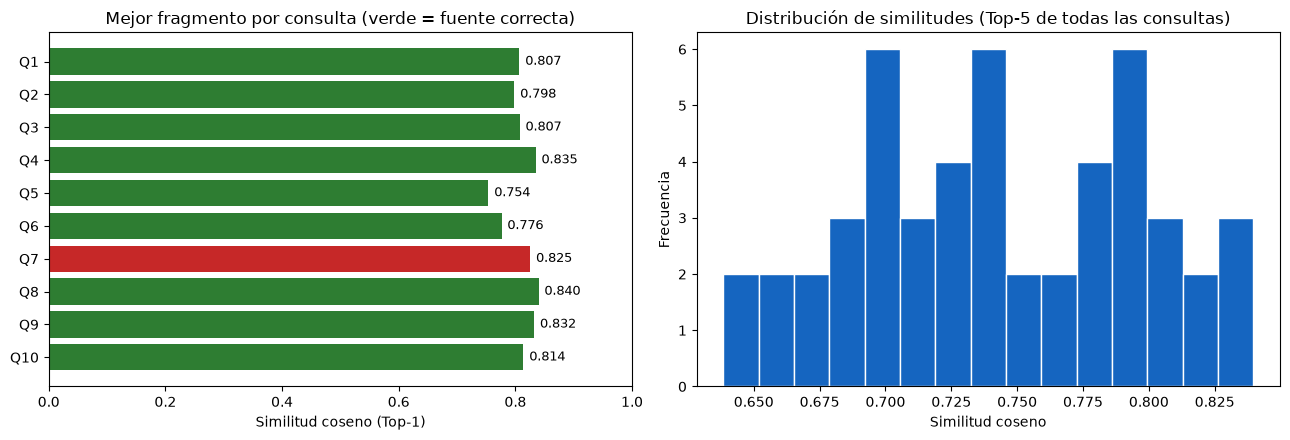

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
labels = [f"Q{i + 1}" for i in range(len(results))][::-1]
colors = ["#2E7D32" if h else "#C62828" for h in results["hit@1"]][::-1]
axes[0].barh(labels, results["sim_top1"][::-1], color=colors)
axes[0].set_xlim(0, 1)
axes[0].set_xlabel("Similitud coseno (Top-1)")
axes[0].set_title("Mejor fragmento por consulta (verde = fuente correcta)")
for i, v in enumerate(results["sim_top1"][::-1]):
    axes[0].text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)

axes[1].hist(np.concatenate(results["top_scores"].values), bins=15, color="#1565C0", edgecolor="white")
axes[1].set_xlabel("Similitud coseno")
axes[1].set_ylabel("Frecuencia")
axes[1].set_title(f"Distribución de similitudes (Top-{K} de todas las consultas)")
plt.tight_layout()
plt.show()

In [16]:
# Control negativo: pregunta fuera de dominio -> se espera una similitud claramente menor
neg_q = "¿Cuál es la receta tradicional de la bandeja paisa?"
neg_hits = semantic_search(neg_q, k=3)
show_results(neg_q, neg_hits)

in_domain = results["sim_top1"].mean()
gap = in_domain - neg_hits[0]["similarity"]
print(f"\nSim. Top-1 en dominio (promedio): {in_domain:.4f} | fuera de dominio: {neg_hits[0]['similarity']:.4f} | brecha: {gap:.4f}")
print("Umbral sugerido para responder 'no tengo información':", round((in_domain + neg_hits[0]['similarity']) / 2, 3))


❓ ¿Cuál es la receta tradicional de la bandeja paisa?
  #1 | sim=0.5976 | protocolo_bioseguridad_consentimiento.md · Introducción
       > Documento de apoyo académico elaborado a partir de lineamientos públicos (OMS, "Mis 5 momentos para la higiene de las manos"; normatividad colombiana: Ley 23 ...
  #2 | sim=0.5793 | protocolo_bioseguridad_consentimiento.md · 7. Consentimiento informado
       La Ley 23 de 1981 (ética médica) establece que el médico debe advertir al paciente sobre los riesgos previstos. Si el paciente no puede decidir, firma su repres...
  #3 | sim=0.5712 | uci_heart_variables · variable trestbps
       Variable «trestbps» del dataset UCI Heart Disease. Presión arterial sistólica en reposo al ingreso, en mmHg. Rango observado: 0 a 200; media 132.1. Valores falt...

Sim. Top-1 en dominio (promedio): 0.8088 | fuera de dominio: 0.5976 | brecha: 0.2112
Umbral sugerido para responder 'no tengo información': 0.703


In [17]:
# Búsqueda filtrada por tipo de fuente y uso de la función SQL match_salud (lista para exponerse como RPC de Supabase)
q = "¿Qué relación hay entre la frecuencia cardíaca máxima y la enfermedad coronaria?"
show_results(q + "  [solo documentos]", semantic_search(q, k=2, doc_type="documento"))
show_results(q + "  [solo resúmenes del dataset]", semantic_search(q, k=2, doc_type="dataset_resumen"))

qvec = embed_query(q)
rows = conn.execute("select source, title, round(similarity::numeric, 4) from match_salud(%s, 3)", (qvec,)).fetchall()
print("\nResultado de la función SQL match_salud():")
for r in rows:
    print("  ", r)


❓ ¿Qué relación hay entre la frecuencia cardíaca máxima y la enfermedad coronaria?  [solo documentos]
  #1 | sim=0.7442 | guia_riesgo_cardiovascular.md · 7. Prueba de esfuerzo
       - **Frecuencia cardíaca máxima teórica:** se estima como 220 menos la edad. Si el paciente no alcanza el 85 % de ese valor, la prueba es submáxima y su capacida...
  #2 | sim=0.7329 | guia_riesgo_cardiovascular.md · 6. Electrocardiograma en reposo
       El electrocardiograma (ECG) en reposo puede ser normal aunque exista enfermedad coronaria. Las alteraciones de la onda ST-T (inversión de la onda T o elevación/...

❓ ¿Qué relación hay entre la frecuencia cardíaca máxima y la enfermedad coronaria?  [solo resúmenes del dataset]
  #1 | sim=0.8047 | uci_heart_resumen · resumen estadístico
       Comparación de pacientes con y sin enfermedad coronaria en UCI Heart Disease (medias): edad 55.9 vs 50.5 años; frecuencia cardíaca máxima (thalch) 128 vs 149 lp...
  #2 | sim=0.7446 | uci_heart_resumen · resumen esta

### Demo en vivo (para el video)
Escribe cualquier pregunta clínica y ejecuta la celda: el vector se calcula en tu equipo y la búsqueda corre en el clúster de Supabase.

In [18]:
pregunta = "¿Qué se le debe explicar a un paciente antes de una biopsia de mama?"
UMBRAL = round((in_domain + neg_hits[0]["similarity"]) / 2, 3)  # punto medio entre dominio y control negativo (~0.70)

t = []
hits = semantic_search(pregunta, k=3, timings=t)
show_results(pregunta, hits, preview=300)
print(f"\n⏱ embedding local: {t[0]['embedding_local_ms']:.0f} ms | búsqueda en Supabase: {t[0]['busqueda_supabase_ms']:.0f} ms")
if hits[0]["similarity"] < UMBRAL:
    print("⚠️ Similitud baja: el asistente debería responder que no tiene información suficiente.")


❓ ¿Qué se le debe explicar a un paciente antes de una biopsia de mama?
  #1 | sim=0.8383 | guia_cancer_mama.md · 8. Comunicación con la paciente
       El resultado de una biopsia se entrega en consulta presencial, con lenguaje claro, explicando el significado del hallazgo, los siguientes pasos y las opciones de tratamiento. La paciente tiene derecho a recibir una copia de su informe, a pedir una segunda opinión y a estar acompañada por una persona...
  #2 | sim=0.7899 | protocolo_bioseguridad_consentimiento.md · 7. Consentimiento informado
       Antes de procedimientos con riesgo, como la prueba de esfuerzo, la gammagrafía, la angiografía coronaria o la biopsia de mama, el paciente debe firmar el consentimiento informado. El documento debe explicar en lenguaje comprensible: - en qué consiste el procedimiento y su objetivo; - los riesgos pre...
  #3 | sim=0.7770 | guia_cancer_mama.md · 1. Propósito y alcance
       Esta guía resume la detección temprana, la clasificación de hallazgos

### Generar el póster con las métricas reales
Esta celda completa `poster/poster_template.html` con los resultados de esta ejecución y crea `poster/poster_ACA1.html`.
Ábrelo en Chrome → **Imprimir** → *Guardar como PDF* (tamaño A3, márgenes «Ninguno», activar «Gráficos de fondo»).

In [ ]:
import datetime, html

AUTORES = "Juan Reyes"                                  # agrega aquí a tu equipo
REPO_URL = "https://github.com/usuario/ESP-rag"         # <- reemplaza por tu repositorio
VIDEO_URL = "https://drive.google.com/file/d/1ru8ZKE5tMXOTMlkO_gYPro5wmIE6AcNi/view?usp=sharing"                # <- reemplaza por el enlace del video

MESES = ["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"]
fmt = lambda x: f"{x:.3f}".replace(".", ",")
pct = lambda x: f"{x:.0%}"
EJ_IDX = [0, 3, 8, 5]  # consultas que se muestran en el póster
ejemplos = ""
for i in EJ_IDX:
    r = results.iloc[i]
    top = semantic_search(r["consulta"], k=1)[0]
    ejemplos += (f"<tr><td>{html.escape(r['consulta'])}</td>"
                 f"<td>{html.escape(top['source'])} · {html.escape(top['title'].split(' - ')[-1])}</td>"
                 f"<td class='num'>{fmt(top['similarity'])}</td></tr>\n")

valores = {
    "AUTORES": AUTORES, "FECHA": f"{MESES[datetime.date.today().month - 1]} de {datetime.date.today().year}",
    "REPO_URL": REPO_URL, "VIDEO_URL": VIDEO_URL,
    "N_VECTORES": str(inventory["vectores"].sum()), "TAMANO_TABLA": size,
    "N_CONSULTAS": str(len(results)), "EJEMPLOS": ejemplos,
    "HIT1": pct(results["hit@1"].mean()), "HIT5": pct(results[f"hit@{K}"].mean()),
    "MRR": fmt(results["rr"].mean()), "SIM_TOP1": fmt(results["sim_top1"].mean()),
    "SIM_NEG": fmt(neg_hits[0]["similarity"]), "GAP": "+" + fmt(gap),
    "LAT_EMB": f"{lat['embedding_local_ms'].mean():.0f} ms", "LAT_DB": f"{lat['busqueda_supabase_ms'].mean():.0f} ms",
    "LAT_TOTAL": f"{lat.sum(axis=1).mean():.0f} ms",
}
poster = (ROOT / "poster" / "poster_template.html").read_text(encoding="utf-8")
for k, v in valores.items():
    poster = poster.replace("{{" + k + "}}", v)
out = ROOT / "poster" / "poster_ACA1.html"
out.write_text(poster, encoding="utf-8")
print("Póster generado:", out)

Póster generado: /Users/juanreyes/ESP-rag/poster/poster_ACA1.html


## 8. Conclusiones

- **Arquitectura híbrida local + nube:** los embeddings se generan localmente con **Ollama + EmbeddingGemma** (costo $0, el texto clínico no sale del equipo) y los vectores se almacenan en **Supabase + pgvector** con índice **HNSW** y métrica **coseno**. Las credenciales se gestionan con `.env` y la tabla tiene RLS activo.
- **Datos:** el corpus combina tres guías/protocolos clínicos con el diccionario y los resúmenes estadísticos de dos datasets UCI (Heart Disease y Breast Cancer Wisconsin), fragmentados por secciones con `RecursiveCharacterTextSplitter` (800/120).
- **Indexación:** inserción por lotes idempotente (*batch upsert*), muy por debajo de los límites del plan gratuito.
- **Validación:** las métricas Hit@k, MRR y similitud coseno, junto con el control negativo, muestran que el sistema recupera los fragmentos pertinentes y diferencia preguntas fuera de dominio; la brecha permite fijar un umbral de «no sé».

**Siguiente paso (RAG completo):** enviar los Top-k fragmentos como contexto a un LLM (local con Ollama, p. ej. `gemma3`, o en la nube) para generar la respuesta final citando la fuente.

In [20]:
conn.close()
print("Conexión cerrada.")

Conexión cerrada.
